In [1]:
%pip install pandas plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import socket
import time
import pandas as pd
import plotly.express as px
import platform

print("Operating System:", platform.system())
print("Python networking environment ready!")

Operating System: Windows
Python networking environment ready!


In [3]:
domain = "google.com"

ip_address = socket.gethostbyname(domain)

print("Domain:", domain)
print("IP Address:", ip_address)

Domain: google.com
IP Address: 172.217.26.46


In [7]:
import socket
import time
import pandas as pd

def traceroute(destination, max_hops=15, timeout=2):

    destination_ip = socket.gethostbyname(destination)

    print("Tracing route to:", destination)
    print("Destination IP:", destination_ip)
    print("-" * 55)

    results = []

    for ttl in range(1, max_hops + 1):

        receiver = socket.socket(
            socket.AF_INET,
            socket.SOCK_RAW,
            socket.IPPROTO_ICMP
        )

        sender = socket.socket(
            socket.AF_INET,
            socket.SOCK_DGRAM,
            socket.IPPROTO_UDP
        )

        receiver.settimeout(timeout)
        receiver.bind(("", 33434))

        # Windows-compatible TTL configuration
        sender.setsockopt(
            socket.IPPROTO_IP,
            socket.IP_TTL,
            ttl
        )

        start_time = time.perf_counter()

        try:
            sender.sendto(
                b"Traceroute test",
                (destination_ip, 33434 + ttl)
            )

            _, address = receiver.recvfrom(512)

            elapsed = (time.perf_counter() - start_time) * 1000

            hop_ip = address[0]

            results.append({
                "Hop": ttl,
                "IP Address": hop_ip,
                "Latency (ms)": round(elapsed, 2)
            })

            print(f"{ttl:2}  {hop_ip:18}  {elapsed:.2f} ms")

            if hop_ip == destination_ip:
                print("\nDestination reached!")
                break

        except socket.timeout:
            print(f"{ttl:2}  * Request timed out")

        finally:
            sender.close()
            receiver.close()

    return pd.DataFrame(results)

In [8]:
df = traceroute("google.com")

df

Tracing route to: google.com
Destination IP: 142.250.182.206
-------------------------------------------------------
 1  * Request timed out
 2  * Request timed out
 3  * Request timed out
 4  * Request timed out
 5  * Request timed out
 6  * Request timed out
 7  * Request timed out
 8  * Request timed out
 9  * Request timed out
10  * Request timed out
11  * Request timed out
12  * Request timed out
13  * Request timed out
14  * Request timed out
15  * Request timed out


""


In [9]:
import socket

try:
    connection = socket.create_connection(
        ("google.com", 443),
        timeout=5
    )
    print("SUCCESS: Google HTTPS server is reachable!")
    connection.close()

except OSError as e:
    print("Connection failed:", e)

SUCCESS: Google HTTPS server is reachable!


In [10]:
import subprocess

result = subprocess.run(
    ["tracert", "-d", "-h", "10", "-w", "1500", "google.com"],
    capture_output=True,
    text=True
)

print(result.stdout)


Tracing route to google.com [2404:6800:4002:830::200e]
over a maximum of 10 hops:

  1     8 ms     4 ms     3 ms  2400:1a00:3b4c:5707::1 
  2    12 ms     5 ms     9 ms  2400:1a00:3b04::1 
  3    13 ms     6 ms    10 ms  2400:1a00:0:1::228 
  4     8 ms    16 ms    11 ms  2400:1a00:0:142::138 
  5    15 ms     5 ms     9 ms  2400:1a00:0:37::46 
  6    24 ms    43 ms    49 ms  2400:1a00:0:41::170 
  7    21 ms    25 ms    31 ms  2400:1a00:0:41::128 
  8    18 ms    14 ms    13 ms  2400:1a00:dccc:1:72:9:128:67 
  9    78 ms    52 ms    70 ms  2404:d180:1a::15 
 10    24 ms    21 ms     *     2001:4860:1:1::126a 

Trace complete.



In [11]:
import subprocess

result = subprocess.run(
    ["tracert", "-4", "-d", "-h", "10", "-w", "1500", "google.com"],
    capture_output=True,
    text=True
)

print(result.stdout)


Tracing route to google.com [142.250.182.206]
over a maximum of 10 hops:

  1     *        2 ms     7 ms  192.168.1.254 
  2     4 ms     6 ms    13 ms  202.166.192.2 
  3     6 ms     8 ms     6 ms  202.79.40.215 
  4     3 ms     5 ms     6 ms  202.79.42.138 
  5     8 ms     5 ms     8 ms  202.79.37.46 
  6     7 ms     8 ms     7 ms  202.79.41.170 
  7    11 ms     7 ms     6 ms  202.79.41.128 
  8    12 ms    13 ms    15 ms  72.9.128.67 
  9    25 ms    35 ms    62 ms  103.225.212.15 
 10     *        *        *     Request timed out.

Trace complete.



In [12]:
import subprocess
import re
import pandas as pd

def windows_traceroute(destination, max_hops=15):

    command = [
        "tracert",
        "-4",
        "-d",
        "-h", str(max_hops),
        "-w", "1500",
        destination
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print(result.stdout)

    return result.stdout


output = windows_traceroute("google.com", 10)


Tracing route to google.com [142.250.182.206]
over a maximum of 10 hops:

  1     4 ms     1 ms     5 ms  192.168.1.254 
  2     6 ms    15 ms    10 ms  202.166.192.2 
  3     6 ms     5 ms     6 ms  202.79.40.215 
  4    28 ms     8 ms     6 ms  202.79.42.138 
  5    11 ms     6 ms     5 ms  202.79.37.46 
  6    13 ms    15 ms    11 ms  202.79.41.170 
  7     7 ms    18 ms    22 ms  202.79.41.128 
  8    10 ms    14 ms    13 ms  72.9.128.67 
  9    35 ms    27 ms    25 ms  103.225.212.15 
 10     *        *        *     Request timed out.

Trace complete.



In [13]:
import re
import pandas as pd

def parse_traceroute(output):

    records = []

    for line in output.splitlines():

        match = re.match(
            r"\s*(\d+)\s+(.*)",
            line
        )

        if not match:
            continue

        hop = int(match.group(1))
        remaining = match.group(2)

        ip_match = re.search(
            r"(\d{1,3}(?:\.\d{1,3}){3})",
            remaining
        )

        if ip_match:
            ip = ip_match.group(1)
        else:
            ip = None

        latencies = re.findall(
            r"(\d+)\s*ms",
            remaining
        )

        records.append({
            "Hop": hop,
            "IP Address": ip,
            "Latency 1 (ms)": int(latencies[0]) if len(latencies) > 0 else None,
            "Latency 2 (ms)": int(latencies[1]) if len(latencies) > 1 else None,
            "Latency 3 (ms)": int(latencies[2]) if len(latencies) > 2 else None
        })

    return pd.DataFrame(records)

In [14]:
df = parse_traceroute(output)

df

,Hop,IP Address,Latency 1 (ms),Latency 2 (ms),Latency 3 (ms)
0,1,192.168.1.254,4.0,1.0,5.0
1,2,202.166.192.2,6.0,15.0,10.0
2,3,202.79.40.215,6.0,5.0,6.0
3,4,202.79.42.138,28.0,8.0,6.0
4,5,202.79.37.46,11.0,6.0,5.0
5,6,202.79.41.170,13.0,15.0,11.0
6,7,202.79.41.128,7.0,18.0,22.0
7,8,72.9.128.67,10.0,14.0,13.0
8,9,103.225.212.15,35.0,27.0,25.0
9,10,NaN,NaN,NaN,NaN


In [16]:
latency_columns = [
    "Latency 1 (ms)",
    "Latency 2 (ms)",
    "Latency 3 (ms)"
]

df["Average Latency (ms)"] = df[latency_columns].mean(axis=1)

df.head()

,Hop,IP Address,Latency 1 (ms),Latency 2 (ms),Latency 3 (ms),Average Latency (ms)
0,1,192.168.1.254,4.0,1.0,5.0,3.333333
1,2,202.166.192.2,6.0,15.0,10.0,10.333333
2,3,202.79.40.215,6.0,5.0,6.0,5.666667
3,4,202.79.42.138,28.0,8.0,6.0,14.000000
4,5,202.79.37.46,11.0,6.0,5.0,7.333333


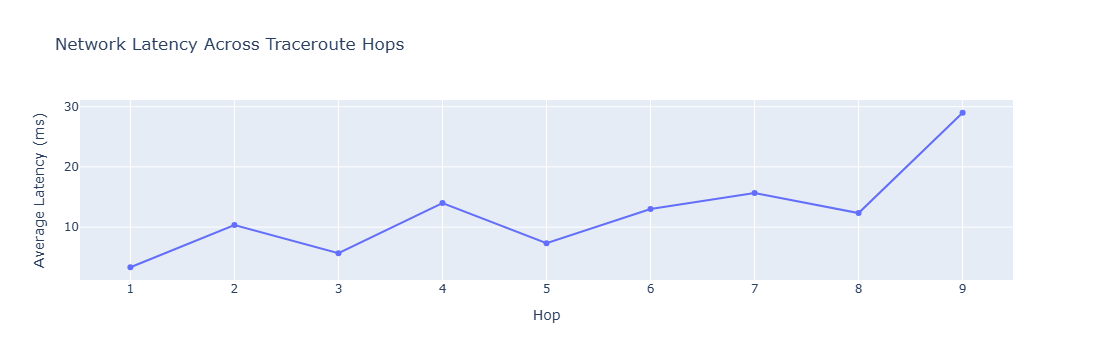

In [17]:
import plotly.express as px

valid_data = df.dropna(
    subset=["Average Latency (ms)"]
)

fig = px.line(
    valid_data,
    x="Hop",
    y="Average Latency (ms)",
    markers=True,
    title="Network Latency Across Traceroute Hops",
    hover_data=["IP Address"]
)

fig.show()

In [18]:
%pip install requests


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import requests

def get_ip_location(ip):

    if not ip:
        return None

    try:
        response = requests.get(
            f"https://ipwho.is/{ip}",
            timeout=10
        )

        data = response.json()

        if not data.get("success"):
            return None

        return {
            "IP Address": ip,
            "Country": data.get("country"),
            "City": data.get("city"),
            "Region": data.get("region"),
            "ISP": data.get("connection", {}).get("isp"),
            "Latitude": data.get("latitude"),
            "Longitude": data.get("longitude")
        }

    except requests.RequestException as e:
        print(f"Lookup failed for {ip}: {e}")
        return None

In [20]:
locations = []

for ip in df["IP Address"].dropna().unique():

    location = get_ip_location(ip)

    if location:
        locations.append(location)

geo_df = pd.DataFrame(locations)

geo_df

,IP Address,Country,City,Region,ISP,Latitude,Longitude
0,202.166.192.2,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
1,202.79.40.215,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
2,202.79.42.138,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
3,202.79.37.46,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
4,202.79.41.170,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
5,202.79.41.128,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
6,72.9.128.67,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
7,103.225.212.15,India,Delhi,Delhi,Interaptus Limited,28.651945,77.231488


In [21]:
final_df = df.merge(
    geo_df,
    on="IP Address",
    how="left"
)

final_df

,Hop,IP Address,Latency 1 (ms),Latency 2 (ms),Latency 3 (ms),Average Latency (ms),Country,City,Region,ISP,Latitude,Longitude
0,1,192.168.1.254,4.0,1.0,5.0,3.333333,NaN,NaN,NaN,NaN,NaN,NaN
1,2,202.166.192.2,6.0,15.0,10.0,10.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
2,3,202.79.40.215,6.0,5.0,6.0,5.666667,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
3,4,202.79.42.138,28.0,8.0,6.0,14.000000,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
4,5,202.79.37.46,11.0,6.0,5.0,7.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
5,6,202.79.41.170,13.0,15.0,11.0,13.000000,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
6,7,202.79.41.128,7.0,18.0,22.0,15.666667,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
7,8,72.9.128.67,10.0,14.0,13.0,12.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
8,9,103.225.212.15,35.0,27.0,25.0,29.000000,India,Delhi,Delhi,Interaptus Limited,28.651945,77.231488
9,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


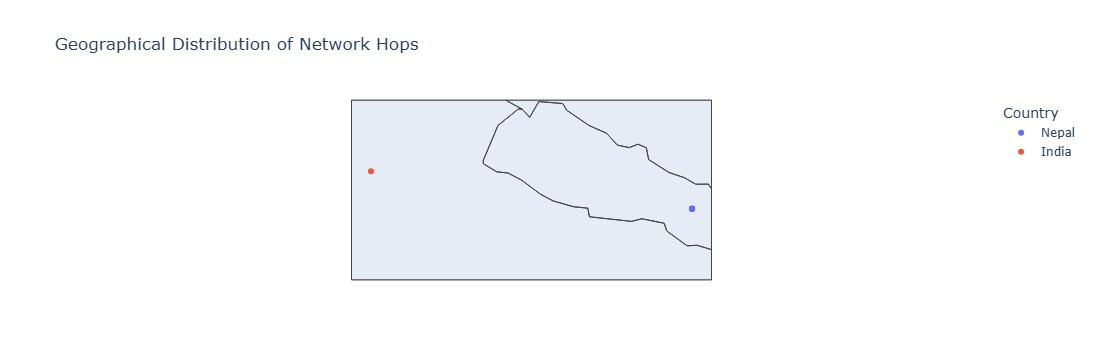

In [22]:
import plotly.express as px

fig = px.scatter_geo(
    geo_df,
    lat="Latitude",
    lon="Longitude",
    hover_name="IP Address",
    hover_data=[
        "Country",
        "City",
        "ISP"
    ],
    color="Country",
    title="Geographical Distribution of Network Hops",
    size_max=15
)

fig.update_geos(
    showcountries=True,
    showland=True,
    fitbounds="locations"
)

fig.show()

In [24]:
def windows_traceroute(destination, max_hops=30):

    command = [
        "tracert",
        "-4",
        "-d",
        "-h", str(max_hops),
        "-w", "800",
        destination
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print(result.stdout)

    return result.stdout

In [25]:
output = windows_traceroute("google.com", 30)


Tracing route to google.com [142.250.182.206]
over a maximum of 30 hops:

  1     9 ms     3 ms     4 ms  192.168.1.254 
  2    17 ms     6 ms     5 ms  202.166.192.2 
  3    15 ms     7 ms     9 ms  202.79.40.215 
  4     9 ms     6 ms     7 ms  202.79.42.138 
  5    11 ms    11 ms     7 ms  202.79.37.46 
  6    10 ms     6 ms     5 ms  202.79.41.170 
  7    16 ms    10 ms     7 ms  202.79.41.128 
  8    11 ms     6 ms     7 ms  72.9.128.67 
  9    35 ms     *       29 ms  103.225.212.15 
 10     *        *        *     Request timed out.
 11    22 ms    24 ms    23 ms  192.178.83.35 
 12    24 ms    30 ms    27 ms  142.251.52.231 
 13    27 ms    26 ms    25 ms  142.250.182.206 

Trace complete.



In [26]:
geo_df = geo_df.merge(
    df[["Hop", "IP Address", "Average Latency (ms)"]],
    on="IP Address",
    how="left"
)

geo_df

,IP Address,Country,City,Region,ISP,Latitude,Longitude,Hop,Average Latency (ms)
0,202.166.192.2,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568,2,10.333333
1,202.79.40.215,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568,3,5.666667
2,202.79.42.138,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568,4,14.000000
3,202.79.37.46,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568,5,7.333333
4,202.79.41.170,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568,6,13.000000
5,202.79.41.128,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568,7,15.666667
6,72.9.128.67,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568,8,12.333333
7,103.225.212.15,India,Delhi,Delhi,Interaptus Limited,28.651945,77.231488,9,29.000000


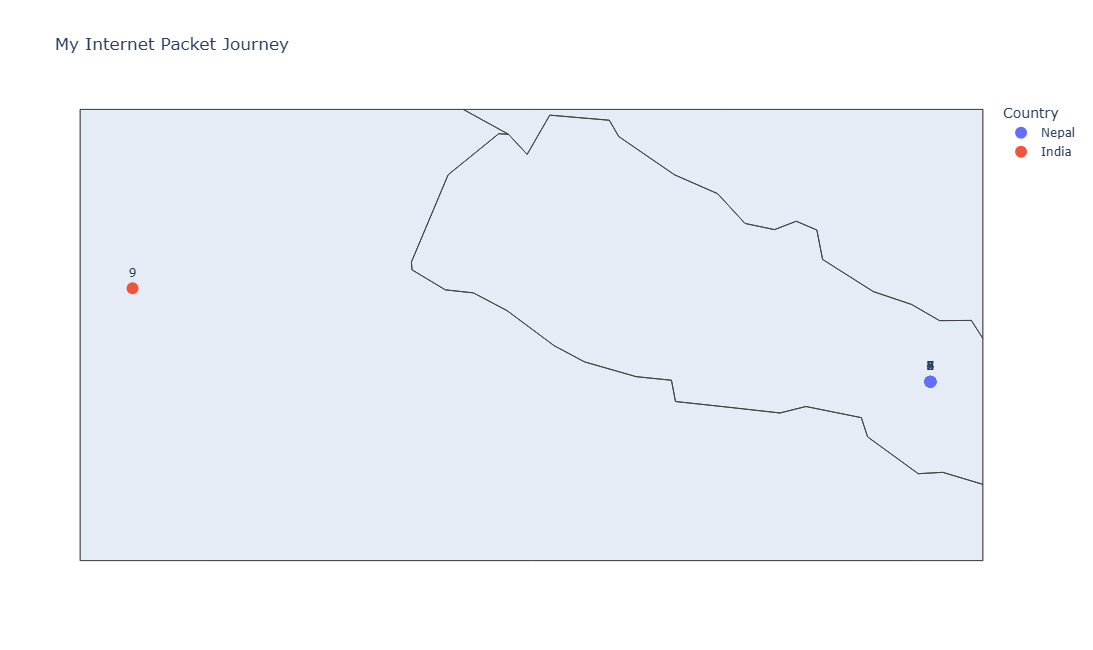

In [27]:
import plotly.express as px

fig = px.scatter_geo(
    geo_df,
    lat="Latitude",
    lon="Longitude",
    color="Country",
    text="Hop",
    hover_name="IP Address",
    hover_data=[
        "Hop",
        "Country",
        "City",
        "ISP",
        "Average Latency (ms)"
    ],
    title="My Internet Packet Journey",
)

fig.update_traces(
    marker=dict(size=12),
    textposition="top center"
)

fig.update_geos(
    showcountries=True,
    showland=True,
    fitbounds="locations"
)

fig.update_layout(height=650)

fig.show()

In [28]:
output = windows_traceroute("web.mit.edu", 30)


Tracing route to e9566.dscb.akamaiedge.net [104.108.227.243]
over a maximum of 30 hops:

  1     7 ms     8 ms     3 ms  192.168.1.254 
  2     7 ms     7 ms     6 ms  202.166.192.2 
  3     6 ms    10 ms     8 ms  202.79.40.215 
  4     9 ms     9 ms    10 ms  202.79.42.138 
  5     9 ms    21 ms    12 ms  202.79.37.46 
  6    14 ms     7 ms    13 ms  202.79.41.170 
  7    24 ms    14 ms     9 ms  202.79.41.128 
  8    15 ms    12 ms     7 ms  72.9.128.67 
  9    28 ms    32 ms    21 ms  103.225.212.15 
 10    25 ms    35 ms    22 ms  45.120.248.23 
 11    24 ms    19 ms    21 ms  104.108.227.243 

Trace complete.



In [29]:
df = parse_traceroute(output)

latency_columns = [
    "Latency 1 (ms)",
    "Latency 2 (ms)",
    "Latency 3 (ms)"
]

df["Average Latency (ms)"] = df[latency_columns].mean(axis=1)

df

,Hop,IP Address,Latency 1 (ms),Latency 2 (ms),Latency 3 (ms),Average Latency (ms)
0,1,192.168.1.254,7,8,3,6.000000
1,2,202.166.192.2,7,7,6,6.666667
2,3,202.79.40.215,6,10,8,8.000000
3,4,202.79.42.138,9,9,10,9.333333
4,5,202.79.37.46,9,21,12,14.000000
5,6,202.79.41.170,14,7,13,11.333333
6,7,202.79.41.128,24,14,9,15.666667
7,8,72.9.128.67,15,12,7,11.333333
8,9,103.225.212.15,28,32,21,27.000000
9,10,45.120.248.23,25,35,22,27.333333


In [30]:
locations = []

for ip in df["IP Address"].dropna().unique():

    location = get_ip_location(ip)

    if location:
        locations.append(location)

geo_df = pd.DataFrame(locations)

geo_df

,IP Address,Country,City,Region,ISP,Latitude,Longitude
0,202.166.192.2,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
1,202.79.40.215,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
2,202.79.42.138,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
3,202.79.37.46,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
4,202.79.41.170,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
5,202.79.41.128,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
6,72.9.128.67,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
7,103.225.212.15,India,Delhi,Delhi,Interaptus Limited,28.651945,77.231488
8,45.120.248.23,India,Delhi,Delhi,EXTREMEBROADBANDSERVICES,28.651954,77.231492
9,104.108.227.243,India,Delhi,Delhi,"Akamai Technologies, Inc.",28.651945,77.231488


In [31]:
final_df = df.merge(
    geo_df,
    on="IP Address",
    how="left"
)

final_df

,Hop,IP Address,Latency 1 (ms),Latency 2 (ms),Latency 3 (ms),Average Latency (ms),Country,City,Region,ISP,Latitude,Longitude
0,1,192.168.1.254,7,8,3,6.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,2,202.166.192.2,7,7,6,6.666667,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
2,3,202.79.40.215,6,10,8,8.000000,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
3,4,202.79.42.138,9,9,10,9.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
4,5,202.79.37.46,9,21,12,14.000000,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
5,6,202.79.41.170,14,7,13,11.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
6,7,202.79.41.128,24,14,9,15.666667,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
7,8,72.9.128.67,15,12,7,11.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
8,9,103.225.212.15,28,32,21,27.000000,India,Delhi,Delhi,Interaptus Limited,28.651945,77.231488
9,10,45.120.248.23,25,35,22,27.333333,India,Delhi,Delhi,EXTREMEBROADBANDSERVICES,28.651954,77.231492


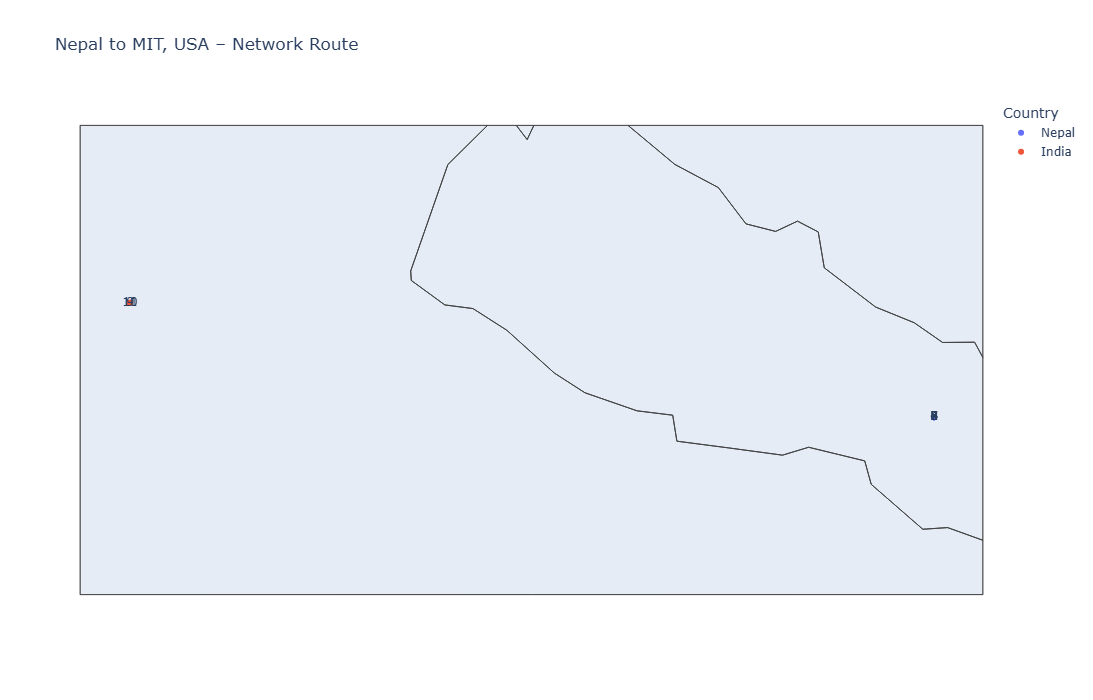

In [32]:
import plotly.express as px

fig = px.scatter_geo(
    final_df.dropna(subset=["Latitude", "Longitude"]),
    lat="Latitude",
    lon="Longitude",
    color="Country",
    text="Hop",
    hover_name="IP Address",
    hover_data=[
        "City",
        "ISP",
        "Average Latency (ms)"
    ],
    title="Nepal to MIT, USA – Network Route"
)

fig.update_geos(
    showcountries=True,
    showland=True,
    projection_type="natural earth"
)

fig.update_layout(height=700)

fig.show()

In [33]:
output = windows_traceroute("128.119.245.12", 30)


Tracing route to 128.119.245.12 over a maximum of 30 hops

  1     3 ms     1 ms     5 ms  192.168.1.254 
  2     3 ms     4 ms     5 ms  202.166.192.2 
  3     4 ms     9 ms     3 ms  202.79.40.215 
  4     9 ms     7 ms     5 ms  202.79.42.138 
  5    20 ms    10 ms     7 ms  202.79.37.46 
  6     8 ms    12 ms    12 ms  202.79.41.170 
  7    11 ms     9 ms    18 ms  202.79.41.128 
  8    16 ms    10 ms    11 ms  72.9.128.67 
  9    14 ms    13 ms    21 ms  125.17.58.157 
 10   172 ms     *        *     182.79.134.223 
 11   184 ms     *      185 ms  77.67.80.189 
 12   275 ms     *      269 ms  89.149.130.37 
 13   271 ms     *      273 ms  65.175.24.206 
 14   271 ms     *      269 ms  69.16.3.0 
 15   275 ms     *      274 ms  192.80.83.101 
 16   275 ms     *      278 ms  128.119.0.216 
 17   265 ms     *      264 ms  128.119.77.233 
 18     *        *        *     Request timed out.
 19   269 ms     *      272 ms  128.119.0.217 
 20   290 ms     *      274 ms  128.119.3.33 
 21

In [34]:
df = parse_traceroute(output)

latency_columns = [
    "Latency 1 (ms)",
    "Latency 2 (ms)",
    "Latency 3 (ms)"
]

df["Average Latency (ms)"] = df[latency_columns].mean(axis=1)

df

,Hop,IP Address,Latency 1 (ms),Latency 2 (ms),Latency 3 (ms),Average Latency (ms)
0,1,192.168.1.254,3.0,1.0,5.0,3.000000
1,2,202.166.192.2,3.0,4.0,5.0,4.000000
2,3,202.79.40.215,4.0,9.0,3.0,5.333333
3,4,202.79.42.138,9.0,7.0,5.0,7.000000
4,5,202.79.37.46,20.0,10.0,7.0,12.333333
5,6,202.79.41.170,8.0,12.0,12.0,10.666667
6,7,202.79.41.128,11.0,9.0,18.0,12.666667
7,8,72.9.128.67,16.0,10.0,11.0,12.333333
8,9,125.17.58.157,14.0,13.0,21.0,16.000000
9,10,182.79.134.223,172.0,NaN,NaN,172.000000


In [35]:
locations = []

for ip in df["IP Address"].dropna().unique():

    location = get_ip_location(ip)

    if location:
        locations.append(location)

geo_df = pd.DataFrame(locations)

In [36]:
final_df = df.merge(
    geo_df,
    on="IP Address",
    how="left"
)

final_df

,Hop,IP Address,Latency 1 (ms),Latency 2 (ms),Latency 3 (ms),Average Latency (ms),Country,City,Region,ISP,Latitude,Longitude
0,1,192.168.1.254,3.0,1.0,5.0,3.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,2,202.166.192.2,3.0,4.0,5.0,4.000000,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
2,3,202.79.40.215,4.0,9.0,3.0,5.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
3,4,202.79.42.138,9.0,7.0,5.0,7.000000,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
4,5,202.79.37.46,20.0,10.0,7.0,12.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
5,6,202.79.41.170,8.0,12.0,12.0,10.666667,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
6,7,202.79.41.128,11.0,9.0,18.0,12.666667,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
7,8,72.9.128.67,16.0,10.0,11.0,12.333333,Nepal,Kathmandu,Bagmati,WorldLink Communications,27.701689,85.320568
8,9,125.17.58.157,14.0,13.0,21.0,16.000000,India,Faridabad,Haryana,Bharti Airtel Limited,28.411243,77.313156
9,10,182.79.134.223,172.0,NaN,NaN,172.000000,United Kingdom,London,England,Bharti Airtel Limited,51.512786,-0.091844


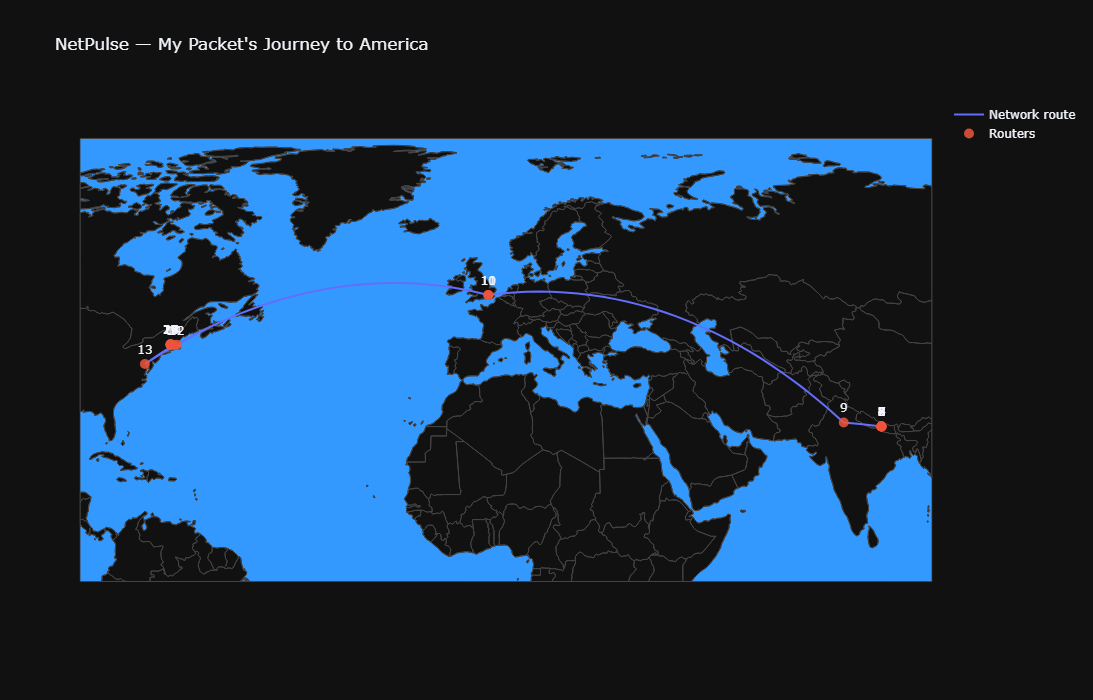

In [37]:
import plotly.graph_objects as go

# Keep only hops with valid geographical coordinates
map_df = final_df.dropna(
    subset=["Latitude", "Longitude"]
).sort_values("Hop")

fig = go.Figure()

# Draw connecting lines between hops
fig.add_trace(go.Scattergeo(
    lat=map_df["Latitude"],
    lon=map_df["Longitude"],
    mode="lines",
    line=dict(width=2, dash="solid"),
    name="Network route",
    hoverinfo="skip"
))

# Plot individual routers
fig.add_trace(go.Scattergeo(
    lat=map_df["Latitude"],
    lon=map_df["Longitude"],
    mode="markers+text",
    text=map_df["Hop"].astype(int).astype(str),
    textposition="top center",
    marker=dict(
        size=10,
        opacity=0.85
    ),
    customdata=map_df[
        ["IP Address", "City", "Country",
         "ISP", "Average Latency (ms)"]
    ],
    hovertemplate=
        "<b>Hop %{text}</b><br>" +
        "IP: %{customdata[0]}<br>" +
        "City: %{customdata[1]}<br>" +
        "Country: %{customdata[2]}<br>" +
        "ISP: %{customdata[3]}<br>" +
        "Average RTT: %{customdata[4]:.2f} ms" +
        "<extra></extra>",
    name="Routers"
))

fig.update_geos(
    projection_type="natural earth",
    showland=True,
    showcountries=True,
    showocean=True,
    fitbounds="locations"
)

fig.update_layout(
    title="NetPulse — My Packet's Journey to America",
    height=700,
    template="plotly_dark"
)

fig.show()